# IND320 - Part 3

**André Olesen**

- GitHub repository: https://github.com/Andreolesen/AndreOlesen-IND320 
- Streamlit app: https://andreolesen-ind320.streamlit.app/



In this part, weather data from open-meteo (ERA5) are downloaded for random locations in a region,
outliers and anomalies in precipitation and temperature are detected, and the reservoir filling from
NVE is analysed with STL decomposition and a spectrogram.

## Imports
All imports are here

In [48]:
import os
import time

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from scipy.fft import dct, idct
from scipy.signal import spectrogram
from scipy.stats import median_abs_deviation
from sklearn.neighbors import LocalOutlierFactor
from statsmodels.tsa.seasonal import STL


## Regions from NVE Atlas
Two sets of regions from NVE Atlas: the electricity areas NO1-NO5 and the precipitation regions RØ, RS, RV, RM
and RN (East = RS + RØ, North = RM + RN). Instead of downloading the shapefiles by hand, I get the same layers as
GeoJSON from the map service behind the Atlas. They are saved in `data/` the first time.

In [49]:
# Map services behind NVE Atlas (same data as the shapefiles you can download in the Atlas)
NVE_REST = "https://kart.nve.no/enterprise/rest/services"
LAYERS = {
    "electricity": (f"{NVE_REST}/Nettomraader/MapServer/0/query", "budomr"),                 # NO 1 - NO 5
    "precipitation": (f"{NVE_REST}/Mapservices/Administrasjon2/MapServer/0/query", "REGION"),  # RØ, RS, RV, RM, RN
}
DATA_DIR = "../data"  # the notebook is in Notebooks/, the data folder is in the repo root


def load_nve_layer(layer):
    """Download one NVE layer as GeoJSON (lon/lat, EPSG:4326), or load it from data/ if it is already saved."""
    path = os.path.join(DATA_DIR, f"nve_{layer}_areas.geojson")
    if not os.path.exists(path):
        url, name_field = LAYERS[layer]
        params = {
            "where": "1=1",               # all features
            "outFields": name_field,      # only the name of the area
            "outSR": 4326,                # longitude/latitude
            "f": "geojson",
            "maxAllowableOffset": 0.001,  # simplify the border a bit, keeps the file small
        }
        response = requests.get(url, params=params, timeout=120)
        response.raise_for_status()
        os.makedirs(DATA_DIR, exist_ok=True)
        with open(path, "wb") as f:
            f.write(response.content)
    gdf = gpd.read_file(path)
    return gdf.rename(columns={LAYERS[layer][1]: "region"})


electricity = load_nve_layer("electricity")
precipitation = load_nve_layer("precipitation")

# Same naming as in the Magasinstatistikk data: "NO 3" -> "NO3"
electricity["region"] = electricity["region"].str.replace(" ", "")

# One table with all ten regions, so the download function only needs a region id
regions = pd.concat(
    [electricity.assign(area_type="electricity"), precipitation.assign(area_type="precipitation")],
    ignore_index=True,
)[["region", "area_type", "geometry"]]
regions

,region,area_type,geometry
0,NO1,electricity,"POLYGON ((11.8091 62.8288, 11.7962 62.8287, 11..."
1,NO2,electricity,"POLYGON ((5.7406 60.3517, 5.7396 60.3536, 5.73..."
2,NO3,electricity,"POLYGON ((10.8738 65.4199, 10.5781 65.4702, 10..."
3,NO4,electricity,"POLYGON ((28.336 71.2942, 27.7178 71.3323, 26...."
4,NO5,electricity,"POLYGON ((7.4148 61.8548, 7.4125 61.8575, 7.38..."
5,RV,precipitation,"POLYGON ((9.0621 62.3726, 9.1047 62.382, 9.142..."
6,RM,precipitation,"POLYGON ((12.5459 66.5972, 12.5448 66.6357, 12..."
7,RN,precipitation,"POLYGON ((31.1043 69.9793, 31.5053 70.1209, 31..."
8,RØ,precipitation,"POLYGON ((10.5607 60.1656, 10.5722 60.1527, 10..."
9,RS,precipitation,"POLYGON ((10.5607 60.1656, 10.5435 60.1652, 10..."


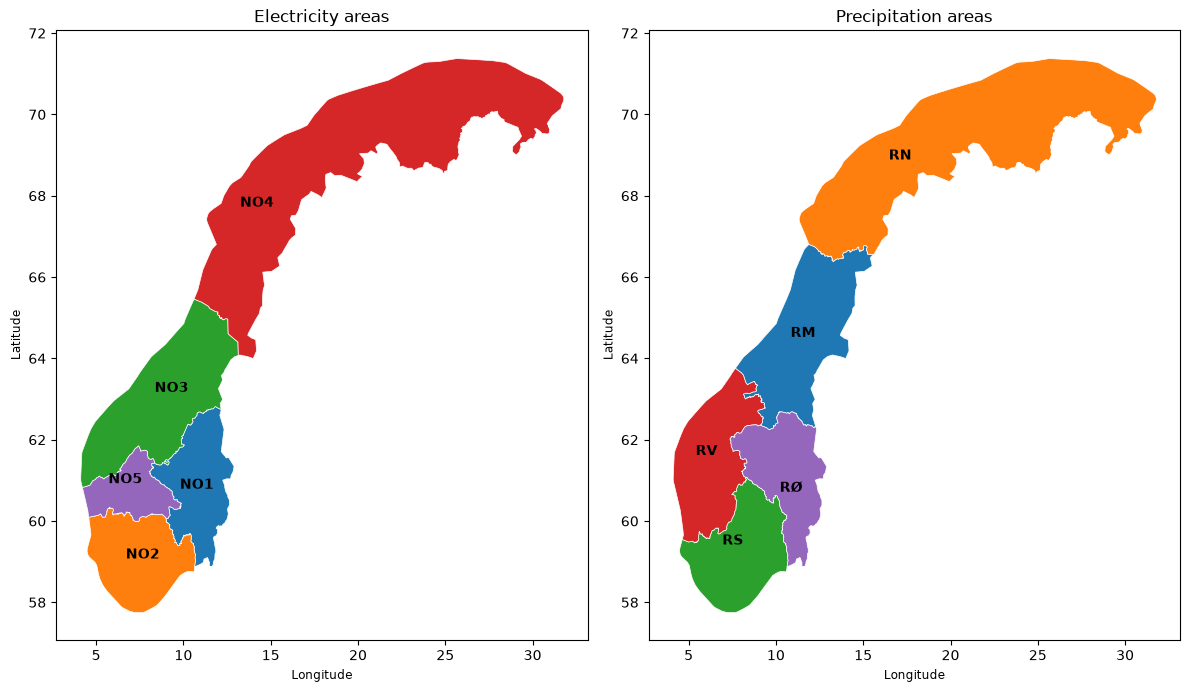

In [50]:
# Map of the two sets of regions side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 7))
for ax, (area_type, group) in zip(axes, regions.groupby("area_type")):
    group.plot(ax=ax, column="region", cmap="tab10", edgecolor="white", linewidth=0.5)
    # Region name in the middle of each area
    for _, row in group.iterrows():
        point = row.geometry.representative_point()
        ax.annotate(row["region"], (point.x, point.y), ha="center", fontsize=10, fontweight="bold")
    ax.set_title(f"{area_type.capitalize()} areas")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
fig.tight_layout()
plt.show()

## Random locations in each region
1000 random locations per region, drawn in UTM 33N (metres) so they are spread evenly over the area.
The seed is fixed, so the points are the same every time.

In [51]:
N_LOCATIONS = 1000
SEED = 42

# Sample in metres (UTM 33N), then convert back to longitude/latitude
sampled = regions.to_crs(25833).geometry.sample_points(size=N_LOCATIONS, rng=SEED)
sampled = sampled.explode(index_parts=False).to_crs(4326)  # one row per point

locations = pd.DataFrame({
    "region": regions.loc[sampled.index, "region"].values,
    "longitude": sampled.x.values,
    "latitude": sampled.y.values,
})

# Dictionary: region id -> table of (longitude, latitude), used by the download function later
region_locations = {region: group[["longitude", "latitude"]].reset_index(drop=True)
                    for region, group in locations.groupby("region")}

locations.groupby("region").size()

region
NO1    1000
NO2    1000
NO3    1000
NO4    1000
NO5    1000
RM     1000
RN     1000
RS     1000
RV     1000
RØ     1000
dtype: int64

In [52]:
# Save the locations, so the Streamlit app can use the same points 
locations.to_csv(os.path.join(DATA_DIR, "region_locations.csv"), index=False)

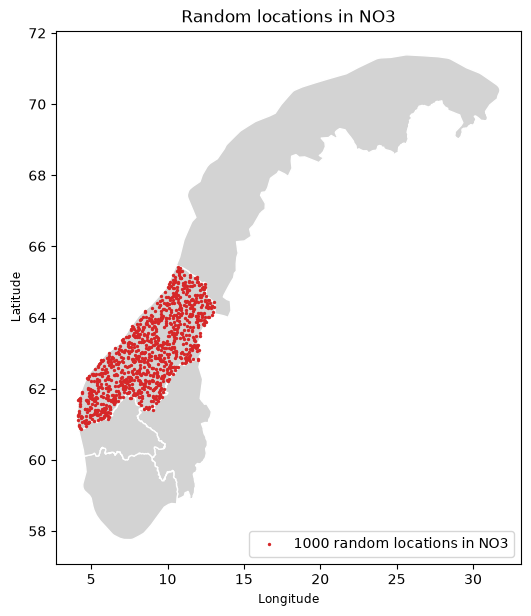

In [53]:
# Check: the random points for NO3 on top of the electricity areas
fig, ax = plt.subplots(figsize=(6, 7))
electricity.plot(ax=ax, color="lightgrey", edgecolor="white")
no3 = region_locations["NO3"]
ax.scatter(no3["longitude"], no3["latitude"], s=2, color="tab:red", label="1000 random locations in NO3")
ax.set_title("Random locations in NO3")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(loc="lower right")
plt.show()

ERA5 has a resolution of 0.25 degrees, so many of the points end up in the same grid cell. The table shows how many
different cells the points in each region cover.

In [54]:
# Round each point to the nearest ERA5 grid cell (0.25 degrees) and count the different cells per region
grid = locations.assign(
    cell_lat=(locations["latitude"] / 0.25).round() * 0.25,
    cell_lon=(locations["longitude"] / 0.25).round() * 0.25,
)
grid.groupby("region")[["cell_lat", "cell_lon"]].apply(lambda g: len(g.drop_duplicates())).rename("era5_cells")

region
NO1    185
NO2    194
NO3    313
NO4    563
NO5    110
RM     284
RN     524
RS     210
RV     222
RØ     187
Name: era5_cells, dtype: int64

## Weather data from open-meteo (ERA5)
The function takes a region id and a time interval, looks up the locations and downloads hourly ERA5 data.
One location for a year counts as about 26 API calls, so all 1000 locations would be far above the daily limit
of 10 000. The function therefore uses a random subset (`n_locations`, default 50). Besides precipitation and
temperature it also downloads rain, snowfall, humidity, wind speed and cloud cover.

In [55]:
WEATHER_URL = "https://archive-api.open-meteo.com/v1/archive"
WEATHER_VARIABLES = [
    "temperature_2m",        # °C, 2 m above ground
    "precipitation",         # mm, rain + snow (as water)
    "rain",                  # mm
    "snowfall",              # cm
    "relative_humidity_2m",  # %
    "wind_speed_10m",        # km/h
    "cloud_cover",           # %
]


def get_weather_batch(batch, start, end, max_retries=5):
    """One API request for a few locations. Waits and tries again if the API says the limit is reached."""
    params = {
        "latitude": ",".join(f"{lat:.4f}" for lat in batch["latitude"]),
        "longitude": ",".join(f"{lon:.4f}" for lon in batch["longitude"]),
        "start_date": start,
        "end_date": end,
        "hourly": ",".join(WEATHER_VARIABLES),
        "models": "era5",
        "timezone": "UTC",
    }
    for attempt in range(max_retries):
        response = requests.get(WEATHER_URL, params=params, timeout=300)
        if response.status_code == 429:  # too many requests: wait a minute and try again
            print("API limit reached, waiting 65 seconds ...")
            time.sleep(65)
            continue
        response.raise_for_status()
        data = response.json()
        return data if isinstance(data, list) else [data]  # one location gives a dict, several give a list
    raise RuntimeError("open-meteo kept refusing the request (limit reached)")


def download_weather(region, start, end, n_locations=50, batch_size=10, seed=SEED):
    """
    Download hourly ERA5 weather for random locations in a region.

    region: region id, e.g. "NO3" or "RM" (looked up in region_locations)
    start, end: dates as "YYYY-MM-DD" (both included)
    n_locations: how many of the 1000 random locations to use (1 = a single location)
    batch_size: locations per API request (small batches stay below the limit of 600 calls per minute)

    Returns a long table with one row per location and hour.
    The result is saved in data/ and loaded from there next time with the same arguments.
    """
    path = os.path.join(DATA_DIR, f"weather_{region}_{start}_{end}_{n_locations}.pkl")
    if os.path.exists(path):
        return pd.read_pickle(path)

    # Look up the locations for the region and pick n of them (fixed seed, so the same every time)
    locations_region = region_locations[region]
    if n_locations < len(locations_region):
        locations_region = locations_region.sample(n_locations, random_state=seed).reset_index(drop=True)

    frames = []
    for first in range(0, len(locations_region), batch_size):
        batch = locations_region.iloc[first:first + batch_size]
        for i, result in enumerate(get_weather_batch(batch, start, end)):
            frame = pd.DataFrame(result["hourly"])
            frame["time"] = pd.to_datetime(frame["time"])
            frame["location"] = first + i
            # The API snaps each location to the nearest ERA5 grid cell
            frame["grid_latitude"] = result["latitude"]
            frame["grid_longitude"] = result["longitude"]
            frames.append(frame)
        print(f"Downloaded {min(first + batch_size, len(locations_region))} of {len(locations_region)} locations")

    weather = pd.concat(frames, ignore_index=True)
    weather.insert(0, "region", region)
    os.makedirs(DATA_DIR, exist_ok=True)
    weather.to_pickle(path)
    return weather

### Testing the function
A small test first: 3 locations in NO3 for one week.

In [56]:
test = download_weather("NO3", "2024-01-01", "2024-01-07", n_locations=3)

print(test.shape)  # 3 locations x 7 days x 24 hours = 504 rows
print(test.groupby("location")[["grid_latitude", "grid_longitude"]].first())
test.head()

(504, 12)
          grid_latitude  grid_longitude
location                               
0                 62.00            5.75
1                 63.75           12.00
2                 61.75            6.50


,region,time,temperature_2m,precipitation,rain,snowfall,relative_humidity_2m,wind_speed_10m,cloud_cover,location,grid_latitude,grid_longitude
0,NO3,2024-01-01 00:00:00,1.8,0.0,0.0,0.0,67,11.2,100,0,62.0,5.75
1,NO3,2024-01-01 01:00:00,1.5,0.0,0.0,0.0,67,11.3,100,0,62.0,5.75
2,NO3,2024-01-01 02:00:00,1.4,0.0,0.0,0.0,68,11.8,100,0,62.0,5.75
3,NO3,2024-01-01 03:00:00,1.0,0.0,0.0,0.0,67,11.9,94,0,62.0,5.75
4,NO3,2024-01-01 04:00:00,1.0,0.0,0.0,0.0,67,11.6,99,0,62.0,5.75


### NO3 for 2024
50 locations in NO3 for 2024. It takes a few minutes the first time, after that it is loaded from `data/`.

In [57]:
weather_no3 = download_weather("NO3", "2024-01-01", "2024-12-31")

print(weather_no3.shape)
print("Locations:", weather_no3["location"].nunique(),
      "| different ERA5 cells:", weather_no3[["grid_latitude", "grid_longitude"]].drop_duplicates().shape[0])
weather_no3.head()

(439200, 12)
Locations: 50 | different ERA5 cells: 43


,region,time,temperature_2m,precipitation,rain,snowfall,relative_humidity_2m,wind_speed_10m,cloud_cover,location,grid_latitude,grid_longitude
0,NO3,2024-01-01 00:00:00,1.8,0.0,0.0,0.0,67,11.2,100,0,62.0,5.75
1,NO3,2024-01-01 01:00:00,1.5,0.0,0.0,0.0,67,11.3,100,0,62.0,5.75
2,NO3,2024-01-01 02:00:00,1.4,0.0,0.0,0.0,68,11.8,100,0,62.0,5.75
3,NO3,2024-01-01 03:00:00,1.0,0.0,0.0,0.0,67,11.9,94,0,62.0,5.75
4,NO3,2024-01-01 04:00:00,1.0,0.0,0.0,0.0,67,11.6,99,0,62.0,5.75


### Regional average
The analyses below use the average over the locations, hour by hour.

In [58]:
# Average over the locations for each hour -> one weather time series for NO3
no3_hourly = weather_no3.groupby("time")[WEATHER_VARIABLES].mean()

no3_hourly.describe().round(2)

,temperature_2m,precipitation,rain,snowfall,relative_humidity_2m,wind_speed_10m,cloud_cover
count,8784.00,8784.00,8784.00,8784.00,8784.00,8784.00,8784.00
mean,5.81,0.20,0.17,0.02,79.12,16.04,76.77
std,6.38,0.27,0.24,0.05,8.10,6.32,22.49
min,-10.44,0.00,0.00,0.00,48.34,3.62,1.80
25%,1.41,0.01,0.01,0.00,74.60,11.18,64.94
50%,5.53,0.10,0.07,0.00,80.44,14.94,83.40
75%,10.98,0.28,0.23,0.01,84.94,19.95,95.26
max,21.46,2.64,2.25,1.05,95.74,47.88,100.00


## Outliers in precipitation (DCT + Statistical Process Control)
First, the slow changes in the precipitation (wet and dry periods longer than about two weeks) are removed with a DCT filter. What is left are the quick changes from hour to hour (SATV). Then I set limits for what is normal: the median ± 3 robust standard deviations. Hours outside the limits are marked as outliers. I use the median instead of the mean, so the hours with heavy rain don’t move the limits themselves. The task says “temperature variations” here, but the section is about precipitation, so I use precipitation.

In [59]:
def precipitation_outliers(series, freq_cutoff=50, n_std=3.0):
    """
    Find outliers in a precipitation series with DCT high-pass filtering and robust SPC limits.

    series: precipitation as a pandas Series with a time index
    freq_cutoff: number of the lowest DCT frequencies that are removed (higher = more is seen as "slow" variation)
    n_std: how many robust standard deviations from the median the limits are

    Returns (figure, table of outliers, summary dictionary).
    """
    values = series.to_numpy(dtype=float)

    # DCT of the whole series. type 2 + norm="ortho" makes idct the exact inverse
    coefficients = dct(values, type=2, norm="ortho")

    # High-pass: remove the lowest frequencies -> seasonally adjusted variations (SATV)
    high_pass = coefficients.copy()
    high_pass[:freq_cutoff] = 0
    satv = idct(high_pass, type=2, norm="ortho")
    slow = values - satv  # the season and slow weather changes

    # Robust statistics for the SATV, estimated from the whole year
    center = np.median(satv)
    sigma = 1.4826 * median_abs_deviation(satv)
    upper = slow + center + n_std * sigma
    lower = slow + center - n_std * sigma
    is_outlier = (satv > center + n_std * sigma) | (satv < center - n_std * sigma)

    # Plot: precipitation, the SPC limits and the outliers in a contrasting colour
    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(series.index, values, color="tab:blue", linewidth=0.6, label="Average precipitation")
    ax.plot(series.index, upper, color="black", linewidth=0.8, linestyle="--", label=f"SPC limits (±{n_std} σ)")
    ax.plot(series.index, lower, color="black", linewidth=0.8, linestyle="--")
    ax.scatter(series.index[is_outlier], values[is_outlier], color="tab:red", s=10, zorder=3, label="Outliers")
    ax.set_title(f"Precipitation with SPC outliers (DCT cut-off {freq_cutoff}, {n_std} σ)")
    ax.set_xlabel("Time (UTC)")
    ax.set_ylabel("Precipitation (mm/h)")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left")
    fig.tight_layout()
    plt.close(fig)  # the figure is returned and shown by the caller

    outliers = pd.DataFrame({
        "precipitation": values[is_outlier],
        "satv": satv[is_outlier],
        "lower_limit": lower[is_outlier],
        "upper_limit": upper[is_outlier],
    }, index=series.index[is_outlier])

    summary = {
        "n_outliers": int(is_outlier.sum()),
        "share_outliers": round(float(is_outlier.mean()), 4),
        "n_above": int((satv > center + n_std * sigma).sum()),
        "n_below": int((satv < center - n_std * sigma).sum()),
        "robust_sigma": round(float(sigma), 4),
    }
    return fig, outliers, summary

### Testing the function
First with the default parameters on the average precipitation for NO3 in 2024.

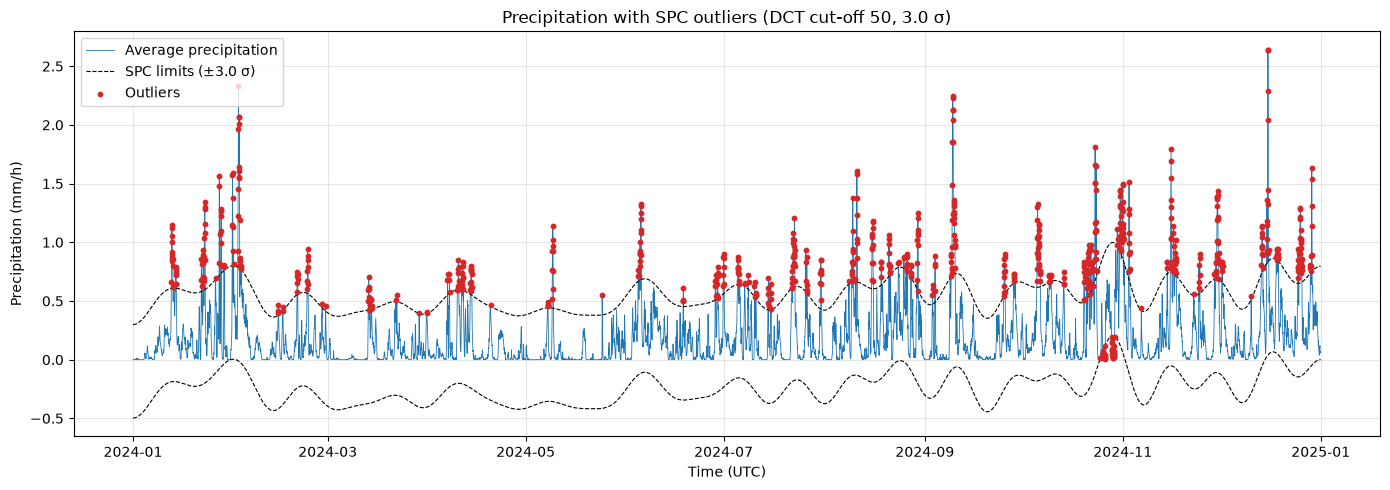

{'n_outliers': 715, 'share_outliers': 0.0814, 'n_above': 671, 'n_below': 44, 'robust_sigma': 0.1327}


,precipitation,satv,lower_limit,upper_limit,above_limit
time,,,,,
2024-12-15 18:00:00,2.640,2.157684,0.039859,0.836149,1.803851
2024-12-15 17:00:00,2.634,2.153119,0.038425,0.834714,1.799286
2024-02-02 12:00:00,2.328,1.896625,-0.011081,0.785208,1.542792
2024-09-09 15:00:00,2.246,1.880172,-0.076628,0.719662,1.526338
2024-09-09 14:00:00,2.230,1.865197,-0.077654,0.718636,1.511364
2024-12-15 19:00:00,2.288,1.804286,0.041258,0.837547,1.450453
2024-09-09 13:00:00,2.128,1.764253,-0.078710,0.717580,1.410420
2024-09-09 16:00:00,2.124,1.757177,-0.075633,0.720657,1.403343
2024-09-09 17:00:00,2.040,1.672212,-0.074669,0.721621,1.318379


In [60]:
fig, precip_outliers, precip_summary = precipitation_outliers(no3_hourly["precipitation"])
display(fig)
print(precip_summary)

# The ten outliers furthest above the limit
precip_outliers.assign(above_limit=precip_outliers["precipitation"] - precip_outliers["upper_limit"]) \
    .sort_values("above_limit", ascending=False).head(10)

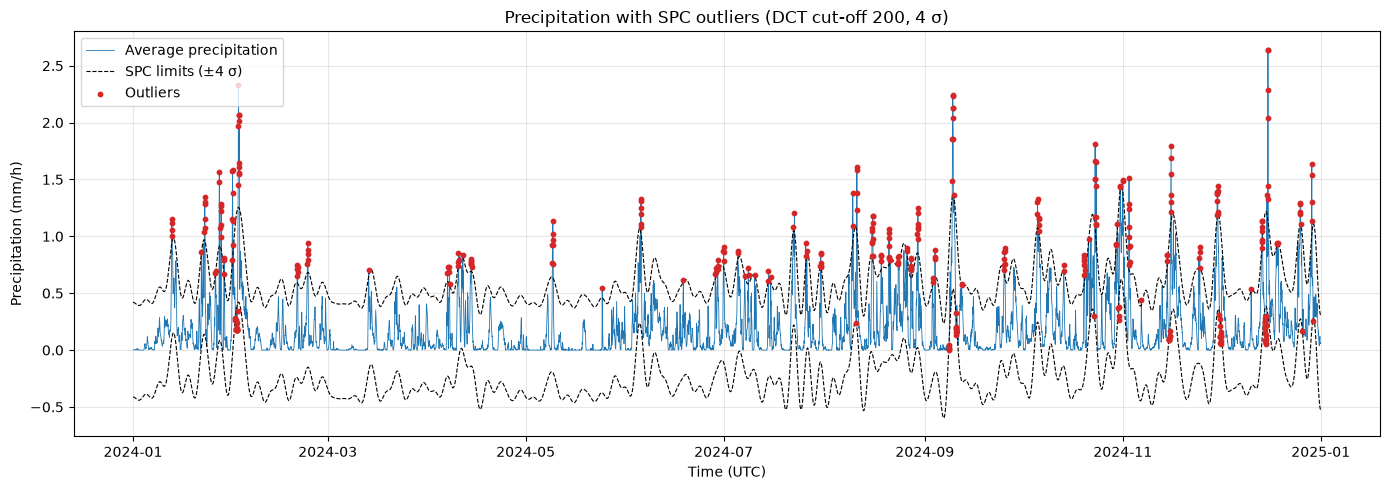

{'n_outliers': 341, 'share_outliers': 0.0388, 'n_above': 273, 'n_below': 68, 'robust_sigma': 0.104}


In [61]:
# Same data with other parameters: a higher cut-off (only variation faster than about 4 days is kept)
# and wider limits (4 σ). This should give fewer outliers.
fig, _, summary_strict = precipitation_outliers(no3_hourly["precipitation"], freq_cutoff=200, n_std=4)
display(fig)
print(summary_strict)

**Interpretation:** About 8 % of the hours are outliers with the default parameters, almost all above the upper
limit (heavy precipitation). The share is high because most hours have little or no precipitation, so the robust σ
gets small. With a higher cut-off and 4 σ it drops to about 4 %.

## Anomalies in temperature (Local Outlier Factor)
LOF marks points that lie in a sparser area than their neighbours. I use time and temperature (both standardised)
as features, so an anomaly is a temperature that is unusual compared to the hours around it.
`contamination` is the share of anomalies (default 1 %).

In [62]:
def temperature_anomalies(series, contamination=0.01, n_neighbors=20):
    """
    Find anomalies in a temperature series with Local Outlier Factor on (time, temperature).

    series: temperature as a pandas Series with a time index
    contamination: proportion of points marked as anomalies
    n_neighbors: number of neighbours LOF uses

    Returns (figure, table of anomalies, summary dictionary).
    """
    # Features: hours since start and temperature, standardised to mean 0 and std 1
    hours = ((series.index - series.index[0]) / pd.Timedelta(hours=1)).to_numpy(dtype=float)
    features = np.column_stack([hours, series.to_numpy(dtype=float)])
    features = (features - features.mean(axis=0)) / features.std(axis=0)

    lof = LocalOutlierFactor(n_neighbors=n_neighbors, contamination=contamination)
    is_anomaly = lof.fit_predict(features) == -1          # -1 = anomaly, 1 = normal
    score = -lof.negative_outlier_factor_                  # higher = more unusual

    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(series.index, series.values, color="tab:blue", linewidth=0.6, label="Average temperature")
    ax.scatter(series.index[is_anomaly], series.values[is_anomaly], color="tab:red", s=12, zorder=3,
               label=f"LOF anomalies ({contamination:.0%})")
    ax.set_title(f"Temperature with LOF anomalies (contamination {contamination}, {n_neighbors} neighbours)")
    ax.set_xlabel("Time (UTC)")
    ax.set_ylabel("Temperature (°C)")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left")
    fig.tight_layout()
    plt.close(fig)

    anomalies = pd.DataFrame({"temperature": series.values[is_anomaly], "lof_score": score[is_anomaly]},
                             index=series.index[is_anomaly]).sort_values("lof_score", ascending=False)

    summary = {
        "n_anomalies": int(is_anomaly.sum()),
        "share_anomalies": round(float(is_anomaly.mean()), 4),
        "coldest_anomaly": round(float(anomalies["temperature"].min()), 1),
        "warmest_anomaly": round(float(anomalies["temperature"].max()), 1),
        "months_with_most_anomalies": anomalies.index.month.value_counts().head(3).to_dict(),
    }
    return fig, anomalies, summary

### Testing the function
With the default 1 % anomalies, and then with 3 % to see that the parameter changes the result.

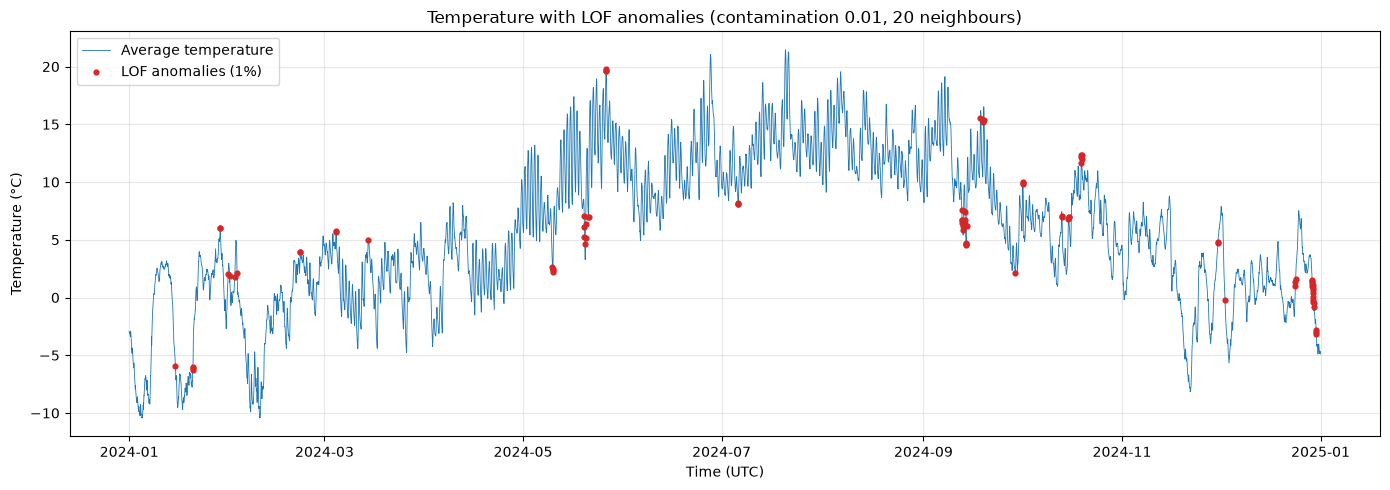

{'n_anomalies': 88, 'share_anomalies': 0.01, 'coldest_anomaly': -6.2, 'warmest_anomaly': 19.8, 'months_with_most_anomalies': {12: 20, 9: 20, 5: 15}}


,temperature,lof_score
time,,
2024-10-19 13:00:00,12.382,2.848627
2024-10-19 14:00:00,12.326,2.754508
2024-10-19 12:00:00,12.172,2.496335
2024-12-24 08:00:00,1.562,2.479746
2024-05-10 04:00:00,2.362,2.435579
2024-05-10 03:00:00,2.226,2.422509
2024-05-19 20:00:00,6.118,2.379638
2024-12-24 07:00:00,1.350,2.366018
2024-12-29 20:00:00,-0.496,2.313008


In [63]:
fig, temp_anomalies, temp_summary = temperature_anomalies(no3_hourly["temperature_2m"])
display(fig)
print(temp_summary)
temp_anomalies.head(10)

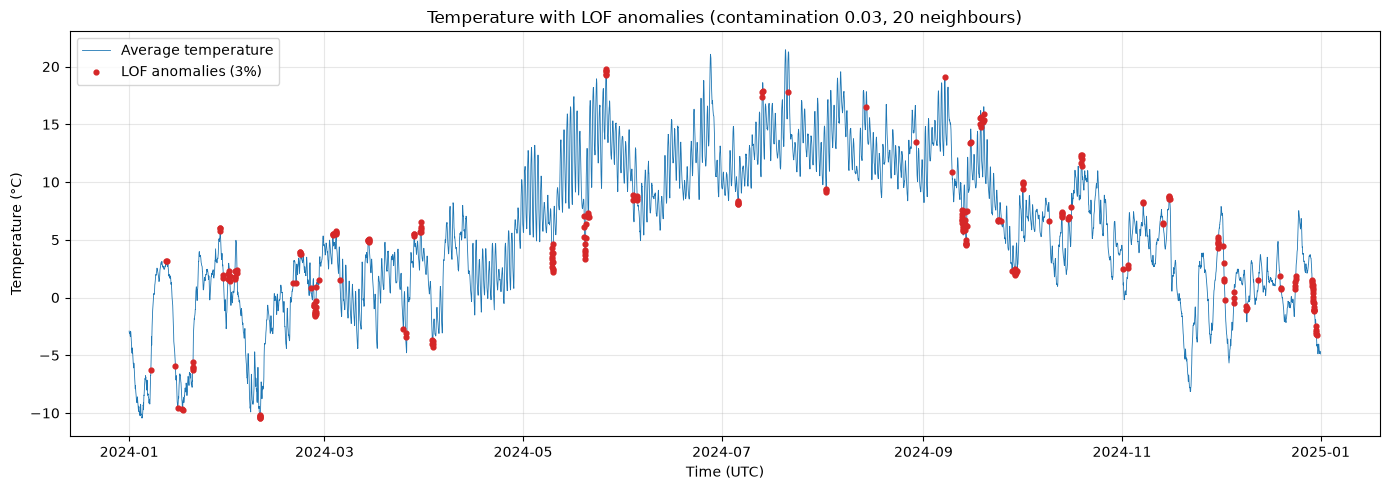

{'n_anomalies': 264, 'share_anomalies': 0.0301, 'coldest_anomaly': -10.4, 'warmest_anomaly': 19.8, 'months_with_most_anomalies': {9: 47, 12: 42, 2: 34}}


In [64]:
# More anomalies (3 %) to check that the parameter works
fig, _, summary_3 = temperature_anomalies(no3_hourly["temperature_2m"], contamination=0.03)
display(fig)
print(summary_3)

**Interpretation:** The anomalies are mostly quick temperature shifts, for example in the middle of May and
September and the warm spell on 19 October. Some points at the end of December are an edge effect, since they only
have neighbours on one side in time.

## Reservoir filling from NVE
STL and the spectrogram use the weekly filling degree for NO3 from the Magasinstatistikk API (same as in part 2),
so it is the same region as the weather data.

In [65]:
# Download the reservoir statistics (all areas) and keep the filling degree for price area NO3
NVE_MAGASIN_URL = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"
response = requests.get(NVE_MAGASIN_URL, timeout=60)
response.raise_for_status()
reservoirs = pd.DataFrame(response.json())
reservoirs["dato_Id"] = pd.to_datetime(reservoirs["dato_Id"])

filling_no3 = (
    reservoirs[(reservoirs["omrType"] == "EL") & (reservoirs["omrnr"] == 3)]
    .set_index("dato_Id")["fyllingsgrad"]
    .sort_index()
    .rename("fill_ratio")
)
print(f"{len(filling_no3)} weeks, from {filling_no3.index.min().date()} to {filling_no3.index.max().date()}")
filling_no3.tail()

1660 weeks, from 1995-01-08 to 2026-10-25


dato_Id
2026-09-27    0.715288
2026-10-04    0.718754
2026-10-11    0.725240
2026-10-18    0.724940
2026-10-25    0.717507
Name: fill_ratio, dtype: float64

## Seasonal-Trend decomposition using LOESS (STL)
STL splits the filling degree into a trend, a seasonal part (period 52 weeks) and a remainder. `seasonal` and
`trend` are the lengths of the smoothers (odd numbers, defaults 13 and 105 weeks), and `robust=True` gives extreme
weeks less weight.

In [66]:
def stl_decomposition(series, period=52, seasonal=13, trend=105, robust=True):
    """
    STL decomposition of a time series, plotted as four panels (original, trend, seasonal, remainder).

    series: pandas Series with a time index (here weekly filling degree)
    period: length of one season in number of observations (52 weeks)
    seasonal, trend: lengths of the seasonal and trend smoothers (odd numbers)
    robust: use robust fitting that reduces the weight of extreme values

    Returns the figure.
    """
    result = STL(series, period=period, seasonal=seasonal, trend=trend, robust=robust).fit()

    parts = [
        ("Original", series),
        ("Trend", result.trend),
        ("Seasonal", result.seasonal),
        ("Remainder", result.resid),
    ]
    fig, axes = plt.subplots(4, 1, figsize=(14, 9), sharex=True)
    for ax, (name, values) in zip(axes, parts):
        if name == "Remainder":
            ax.scatter(values.index, values, s=3)       # points make single weeks easier to see
            ax.axhline(0, color="black", linewidth=0.5)
        else:
            ax.plot(values.index, values, linewidth=0.9)
        ax.set_ylabel(name)
        ax.grid(alpha=0.3)
    axes[-1].set_xlabel("Date")
    fig.suptitle(f"STL of filling degree (period={period}, seasonal={seasonal}, trend={trend}, robust={robust})")
    fig.tight_layout()
    plt.close(fig)
    return fig

### Testing the function
With the default parameters, and then with a shorter seasonal smoother and without robust fitting.

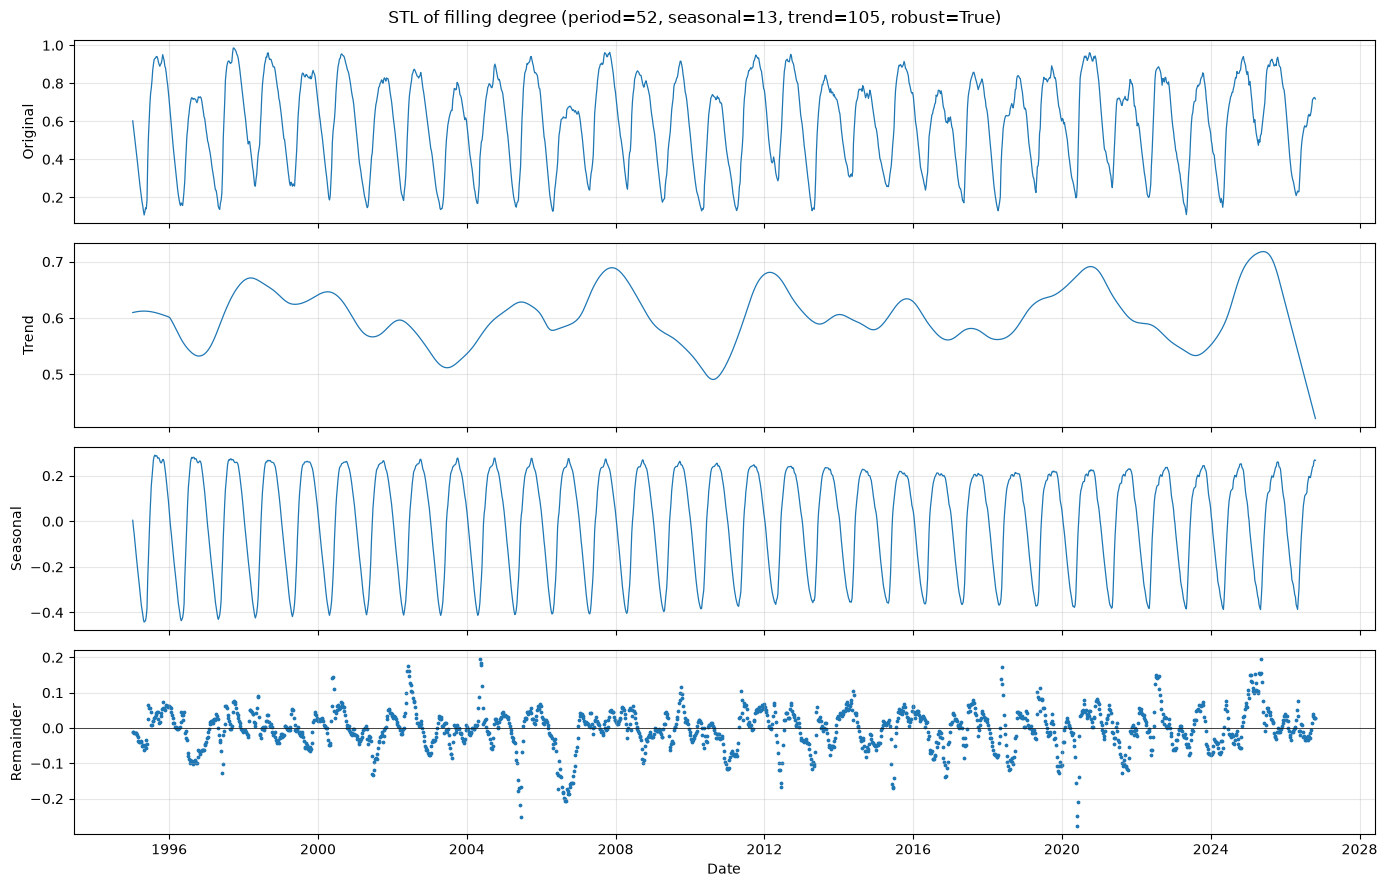

In [67]:
display(stl_decomposition(filling_no3))

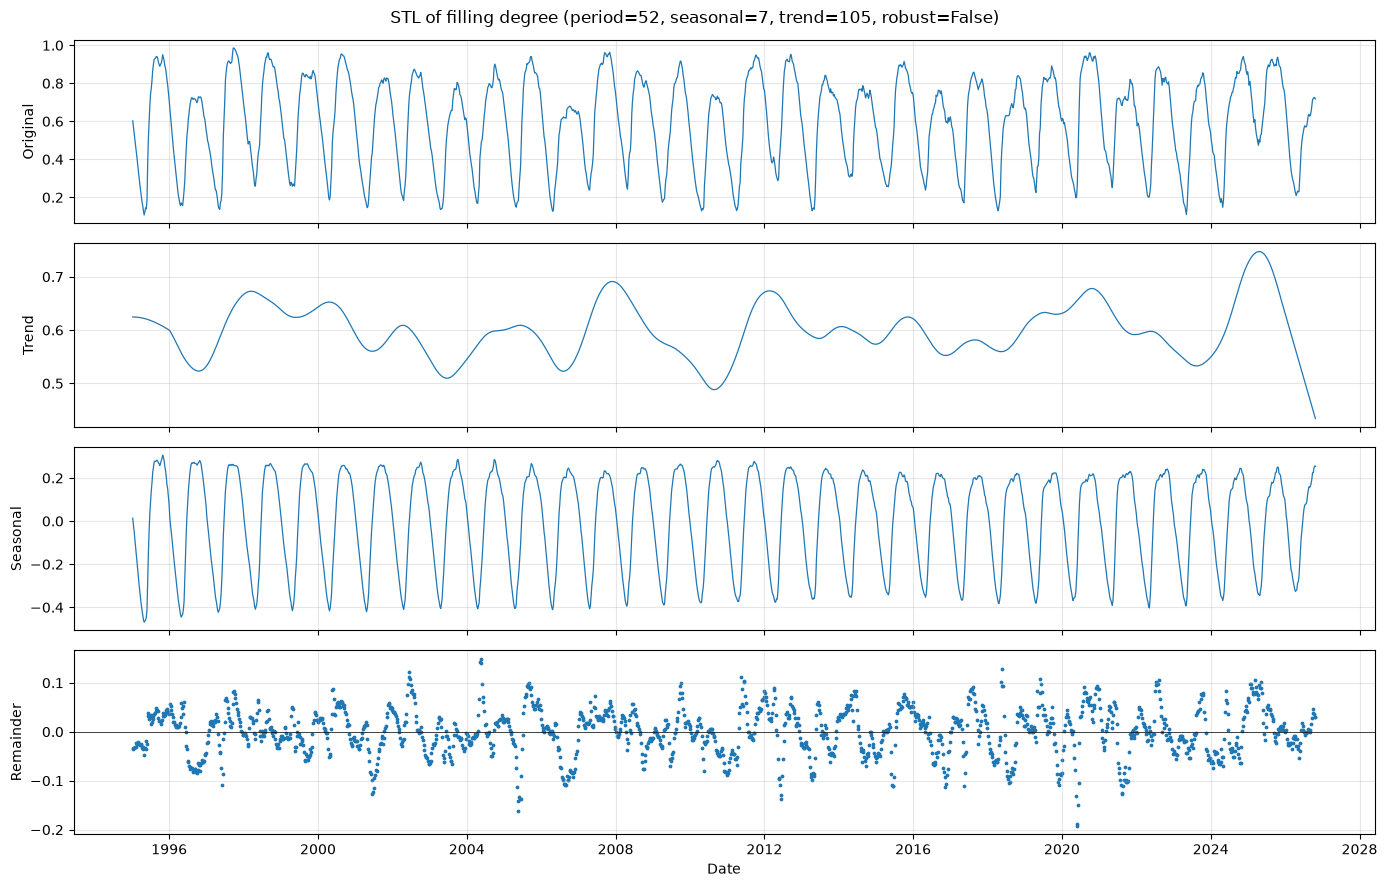

In [68]:
# Shorter seasonal smoother (the yearly pattern can change faster) and no robust fitting
display(stl_decomposition(filling_no3, seasonal=7, robust=False))

**Interpretation:** The season is clear: the filling is lowest in April-May before the snow melts and highest in
September-October. The drop in the trend at the very end is mostly an edge effect. The remainder shows unusual
weeks, for example in dry or wet years. Other parameters give almost the same result.

## Spectrogram
The spectrogram shows which rhythms are in the series and how they change over time. `window_length` (default
104 weeks) must be longer than a year to see the yearly cycle, and `overlap` (default 78 weeks) is how much the
windows overlap. The frequency axis is in cycles per year.

In [69]:
def filling_spectrogram(series, window_length=104, overlap=78, max_frequency=6):
    """
    Spectrogram of a weekly time series.

    series: pandas Series with a weekly time index
    window_length: weeks per window
    overlap: weeks shared by two neighbouring windows (must be smaller than window_length)
    max_frequency: highest frequency (cycles per year) shown in the plot

    Returns the figure.
    """
    weeks_per_year = 365.25 / 7
    frequencies, times, power = spectrogram(
        series.to_numpy(dtype=float),
        fs=weeks_per_year,        # samples per year -> frequencies in cycles per year
        nperseg=window_length,
        noverlap=overlap,
        detrend="constant",       # remove the mean in each window, so frequency 0 doesn't dominate
        scaling="spectrum",
    )
    # times are in years after the first week -> convert to dates for the x-axis
    dates = series.index[0] + pd.to_timedelta(times * 365.25, unit="D")

    fig, ax = plt.subplots(figsize=(14, 5))
    mesh = ax.pcolormesh(dates, frequencies, 10 * np.log10(power + 1e-12), shading="auto", cmap="viridis")
    ax.set_ylim(0, max_frequency)
    ax.set_title(f"Spectrogram of filling degree (window {window_length} weeks, overlap {overlap} weeks)")
    ax.set_xlabel("Date (centre of window)")
    ax.set_ylabel("Frequency (cycles per year)")
    fig.colorbar(mesh, ax=ax, label="Power (dB)")
    fig.tight_layout()
    plt.close(fig)
    return fig

### Testing the function
With the default two-year window, and then with a one-year window and 50 % overlap.

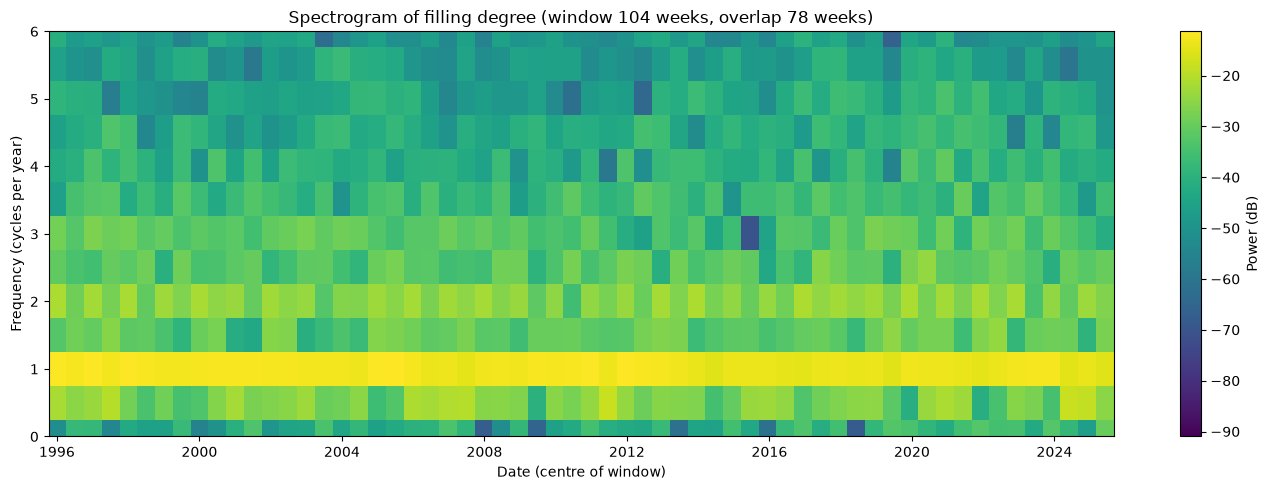

In [70]:
display(filling_spectrogram(filling_no3))

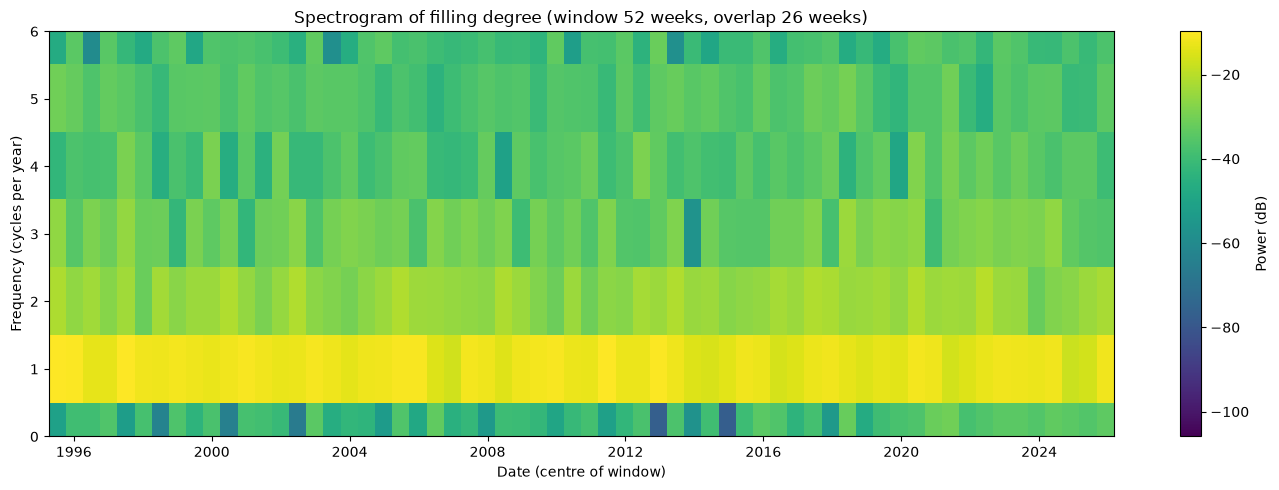

In [71]:
# Shorter window: better time resolution, but coarser frequency resolution (only 1 cycle per year steps)
display(filling_spectrogram(filling_no3, window_length=52, overlap=26))

**Interpretation:** The strongest power is at 1 cycle per year in the whole period, which is the yearly cycle.
The weaker band at 2 cycles per year is there because the yearly pattern is not a pure sine wave. A one-year window
gives wider bands, but more detail in time.

## AI usage

I used Claude (Opus 5.5) as an assistant in this part. Claude helped me understand the task, find the key information I needed and explain alot of the techinchal parts of the task. And helped me structure the notebook. As well as came with suggestions on what methods was best to do the task in the best way possible. It also helped write code for this task. 


## Log


The first step was to get the regions from NVE Atlas. Instead of downloading the shapefiles by hand, I used the
map services behind the Atlas, so the electricity areas and the precipitation regions are downloaded in the code
and saved locally. The 1000 random points per region are drawn in metres, so they are spread evenly over the area.
Many of the points still end up in the same ERA5 grid cell, since the weather data has a resolution of about 28 km.

The weather download was limited by open-meteo. One location for a whole year counts as around 26 requests, so all
1000 locations would be far above the daily limit. The function therefore uses 50 random locations, sends them in
small batches and waits if the limit is reached. The result is saved to a file, so the notebook does not have to
download everything again.

The task text was a bit unclear, since the precipitation part talks about temperature variations. I used DCT and
SPC on precipitation and LOF on temperature, as the headings say. The DCT part was the most technical for me. The
idea is to remove the slow changes, like wet and dry periods, and then set limits for what is normal for the quick
changes from hour to hour. About 8 % of the hours became outliers, which was more than I expected. The reason is
that most hours have little or no rain, so the limits end up low. For the temperature, LOF mostly found quick
shifts, and some points at the end of December are an edge effect.

For STL and the spectrogram I reused the NVE API from part 2 and the filling degree for NO3, which goes back to
1995. Both methods show a strong yearly cycle, and the spectrogram showed how the window length is a trade-off
between detail in time and detail in frequency.

In the Streamlit app I added two new pages with tabs, one for STL and the spectrogram and one for the outlier
and anomaly analysis of the weather data. The functions are the same as in the notebook. The area is a global
setting, chosen on the reservoir page and shared with the new pages, while the year and the parameters are local.
The weather download is a hidden part of the app that runs when the page opens, uses only 5 locations and is
cached. After seeing a classmate's app in the peer review, I also added key figures to the home page, which
compare the filling in Norway this week with last year and with a normal year.